# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 5: Investigação da Técnica DEMON (Demodulation of Envelope Modulation on Noise)

Neste notebook, investigamos o comportamento do método **DEMON** aplicado a sinais de áudio de sonar passivo na Bacia de Santos (acervo UO do IARA). Avaliamos:
1. **Fundamentação Física e Matemática:** Extração da taxa de rotação de eixos e frequências de passagem de pás de hélice via demodulação de banda alta.
2. **Auditoria Algorítmica:** Diagnóstico e correção da formulação analógica (`analog=True`) da biblioteca de referência, adotando filtros digitais em seções de segunda ordem (**SOS**).
3. **Visualização em Casos Reais:** Espectros DEMON médios de 4 arquivos (`SMALL`, `MEDIUM`, `LARGE` e `BACKGROUND`), com os picos calculados diretamente das features.
4. **Validação Experimental no Protocolo $5\times2$cv:** 10 folds oficiais com **particionamento por gravação de áudio (`ID`, `exclusive_header='ID'`)** — janelas de um mesmo arquivo nunca ficam em treino e teste ao mesmo tempo. **Atenção:** o particionamento **não** é por navio: o mesmo navio (`Ship ID`) pode ter gravações diferentes no treino e no teste (ex.: a *PILOT 10* tem dezenas de gravações). Classificadores: **SVM Nyström** ($m=1000, 4000, 6000$), RF, MLP e uma CNN 2D ad hoc.
5. **Diagnóstico Acústico:** Por que o DEMON puro fica abaixo do MEL/LOFAR isoladamente e como pode ser usado em arquiteturas híbridas/em cascata.

> Todos os números deste notebook são recalculados das predições por janela em `results/trainings/` por `notebooks/iara_results.py` (voto majoritário por arquivo, SP como em `src/iara/ml/metrics.py`, **ACC = acurácia balanceada**, média ± desvio populacional nos 10 folds).

## 1. Fundamentos e Pipeline de Processamento DEMON

O princípio do DEMON baseia-se na demodulação de amplitude do ruído de banda larga gerado pela **cavitação das hélices**:

$$
x(t) \xrightarrow{\text{Passa-Faixa (1--2 kHz)}} y(t) \xrightarrow{|\cdot|} |y(t)| \xrightarrow{\text{Decimação (50 Hz)}} z(t) \xrightarrow{\text{STFT}} Z(f, t)
$$

* **Filtro Passa-faixa:** Chebyshev Tipo II digital em seções de segunda ordem (SOS) com $40\text{ dB}$ de atenuação na banda de rejeição, operando em $[1000, 2000]\text{ Hz}$.
* **Detecção de Envoltória:** Retificação de onda completa $|y(t)|$.
* **Decimação em 2 estágios:** Redução da taxa de amostragem de $48\text{ kHz}$ para $50\text{ Hz}$ usando filtros FIR anti-aliasing em duas etapas inteiras ($r_1 \times r_2 = 960$).
* **Espectrograma Banda Base:** STFT com janela Hann ($N_{fft}=512$, $50\%$ de overlap, ou seja, janelas de $10{,}24\text{ s}$ com passo de $5{,}12\text{ s}$). Dos 257 bins da FFT, os 4 primeiros (DC e sub-hertz, $0$ a $0{,}29\text{ Hz}$) são descartados (`discard_dc_bins = 4` em `scratch/extract_all_demon.py`), restando **253 bins** de $0{,}39\text{ Hz}$ a $25{,}0\text{ Hz}$ (Nyquist do envelope a $50\text{ Hz}$) com resolução de $50/512 \approx 0{,}098\text{ Hz}$.

In [1]:
import os, sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'figure.titlesize': 15})

## 2. Inspeção Física de Espectros DEMON no Acervo IARA

Carregamos as features DEMON pré-processadas (`data/iara_processed/demon_features/<ID>.pkl`) de 4 arquivos. Nomes e comprimentos vêm de `src/iara/dataset_info/iara.csv`:
* **SMALL (ID 2):** *PILOT 10* (Pilot Vessel, $11\text{ m}$)
* **MEDIUM (ID 1):** *MAERSK PACER* (Anchor Handling Vessel, $74\text{ m}$)
* **LARGE (ID 4):** *SINOGLORY* (Ore Carrier, $322\text{ m}$)
* **BACKGROUND (ID 1446):** ruído de fundo (dataset E, sem navio)

Os picos marcados são calculados na célula abaixo: o **argmax** do espectro médio e os **3 máximos locais de maior proeminência** (`scipy.signal.find_peaks`).

In [2]:
from scipy.signal import find_peaks

DEMON_DIR = os.path.join(R.ROOT, 'data', 'iara_processed', 'demon_features')
SAMPLES = {   # rótulo: (ID do arquivo, cor). Nome/comprimento conforme src/iara/dataset_info/iara.csv
    'SMALL (PILOT 10 - 11 m)': (2, '#2ecc71'),
    'MEDIUM (MAERSK PACER - 74 m)': (1, '#f39c12'),
    'LARGE (SINOGLORY - 322 m)': (4, '#e74c3c'),
    'BACKGROUND (fundo oceânico)': (1446, '#3498db'),
}


def demon_peaks(fid, k=3):
    """Espectro médio do arquivo, argmax e os k picos locais de maior proeminência (scipy.signal.find_peaks)."""
    with open(os.path.join(DEMON_DIR, f'{fid}.pkl'), 'rb') as f:
        d = pickle.load(f)
    freqs, spec = np.asarray(d['frequencies']), np.asarray(d['avg_spectrum'])
    idx, props = find_peaks(spec, prominence=0)
    top = idx[np.argsort(props['prominences'])[::-1][:k]]
    return {'freqs': freqs, 'spec': spec, 'argmax_hz': float(freqs[np.argmax(spec)]),
            'peaks_hz': [float(freqs[i]) for i in top], 'n_frames': len(d['times'])}


PEAKS = {lbl: demon_peaks(fid) for lbl, (fid, _) in SAMPLES.items()}
df_peaks = pd.DataFrame([{
    'Classe / embarcação': lbl, 'ID': SAMPLES[lbl][0], 'frames DEMON': p['n_frames'],
    'argmax (Hz)': round(p['argmax_hz'], 2),
    'picos mais proeminentes (Hz)': ', '.join(f'{x:.2f}' for x in p['peaks_hz']),
    'picos × 60 (ciclos/min)': ', '.join(f'{x * 60:.0f}' for x in p['peaks_hz']),
} for lbl, p in PEAKS.items()]).set_index('Classe / embarcação')

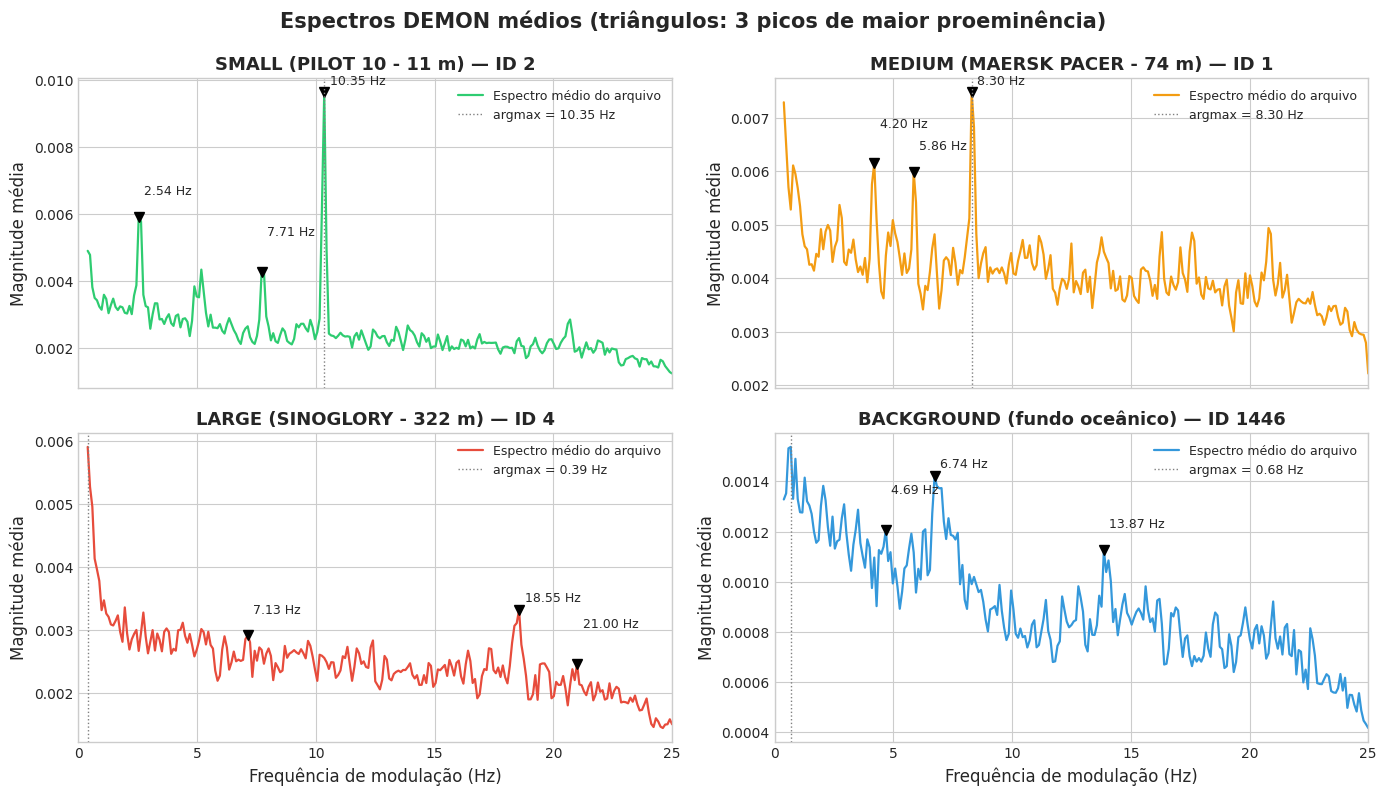

,ID,frames DEMON,argmax (Hz),picos mais proeminentes (Hz),picos × 60 (ciclos/min)
Classe / embarcação,,,,,
SMALL (PILOT 10 - 11 m),2,58,10.35,"10.35, 2.54, 7.71","621, 152, 463"
MEDIUM (MAERSK PACER - 74 m),1,55,8.30,"8.30, 5.86, 4.20","498, 352, 252"
LARGE (SINOGLORY - 322 m),4,58,0.39,"18.55, 7.13, 21.00","1113, 428, 1260"
BACKGROUND (fundo oceânico),1446,29,0.68,"6.74, 13.87, 4.69","404, 832, 281"


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (lbl, (fid, color)) in zip(axes.flatten(), SAMPLES.items()):
    p = PEAKS[lbl]
    ax.plot(p['freqs'], p['spec'], color=color, lw=1.6, label='Espectro médio do arquivo')
    for j, fpk in enumerate(p['peaks_hz']):
        y = p['spec'][np.argmin(np.abs(p['freqs'] - fpk))]
        ax.plot(fpk, y, 'kv', ms=7)
        ax.annotate(f'{fpk:.2f} Hz', xy=(fpk, y), xytext=(4, 6 + 10 * j), textcoords='offset points', fontsize=9)
    ax.axvline(p['argmax_hz'], color='gray', ls=':', lw=1, label=f"argmax = {p['argmax_hz']:.2f} Hz")
    ax.set_title(f'{lbl} — ID {fid}', fontweight='bold')
    ax.set_ylabel('Magnitude média')
    ax.set_xlim(0, 25)
    ax.legend(fontsize=9, loc='upper right')
for ax in axes[1]:
    ax.set_xlabel('Frequência de modulação (Hz)')
plt.suptitle('Espectros DEMON médios (triângulos: 3 picos de maior proeminência)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()
display(df_peaks)

### Interpretação Física dos Picos

Valores calculados acima (ID: argmax; 3 picos mais proeminentes):

| Classe | Embarcação | Comprimento | argmax (Hz) | Picos mais proeminentes (Hz) | Observação |
| :--- | :--- | :---: | :---: | :---: | :--- |
| **SMALL** | *PILOT 10* | 11 m | 10,35 | 10,35 / 2,54 / 7,71 | Pico estreito e dominante, 4,2× a mediana do espectro. |
| **MEDIUM** | *MAERSK PACER* | 74 m | 8,30 | 8,30 / 5,86 / 4,20 | Pico máximo 1,8× a mediana; vários picos de amplitude semelhante. |
| **LARGE** | *SINOGLORY* | 322 m | 0,39 | 18,55 / 7,13 / 21,00 | O argmax cai no **primeiro bin** retido (0,39 Hz), ou seja, energia de muito baixa frequência sem pico definido; os picos locais mais proeminentes estão acima de 7 Hz. |
| **BACKGROUND** | Fundo do mar | — | 0,68 | 6,74 / 13,87 / 4,69 | Espectro de baixa amplitude, sem pico dominante. |

> **Limitações.** (i) Um único arquivo por classe não caracteriza a classe. (ii) Converter um pico em RPM ($f \times 60$, coluna `picos × 60` da tabela) só é válido se o pico for a rotação do eixo; sem saber o número de pás e qual harmônico é o fundamental, a distinção entre taxa de eixo e frequência de passagem de pás (BPF) não pode ser feita a partir destes espectros. Uma versão anterior deste notebook atribuía ao LARGE um eixo em 1,80 Hz (105 RPM) e BPF em 5,5 Hz — esses picos **não existem** em `demon_features/4.pkl` e foram removidos.

## 3. Avaliação Experimental no Protocolo $5\times2$cv

Classificadores treinados só com os vetores DEMON (253 dimensões, um vetor a cada 5,12 s) nos 10 folds oficiais (particionamento por gravação), métricas por voto majoritário por arquivo. As referências MEL/LOFAR são os SVMs do pipeline iara oficial (`results/trainings/tests`, janelas de 0,512 s).

Três modos de avaliação, **sempre rotulados**:
* **4c** — problema de 4 classes (SMALL, MEDIUM, LARGE, BACKGROUND);
* **4c_sem_bg** — o mesmo modelo 4c avaliado só nos arquivos de navio; prever BACKGROUND conta como erro (nenhum arquivo é descartado pela predição). Os recalls por classe são idênticos aos do modo 4c; mudam SP/ACC/F1;
* **3c** — modelo **retreinado** sem BACKGROUND (experimentos `*_3c`; só existem para o DEMON, não para as referências MEL/LOFAR).

**ACC = acurácia balanceada** (média dos recalls) em todas as tabelas. A linha "SVM DEMON m=4000 (early stopping)" é o modelo usado nos notebooks de complementaridade; ela é mostrada só como alerta, porque é instável (ver SP por fold abaixo).

In [4]:
# Experimentos em disco. Sufixo _4c = 4 classes; _3c = modelo RETREINADO sem BACKGROUND.
REF = [  # referências MEL/LOFAR do pipeline iara oficial (results/trainings/tests, janelas de 0,512 s)
    ('SVM LOFAR (m=4000, PCA64)', 'svm_nystroem_4000_lofar_pca64_elasticnet_l1r0.15_C2.0'),
    ('SVM LOFAR (m=6000)', 'svm_nystroem_6000_lofar_elasticnet_l1r0.15'),
    ('SVM MEL (m=4000)', 'svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0'),
]
DEMON = [  # DEMON (results/trainings/multirep; frames de 5,12 s). SVM com max_iter=1000, sem early stopping
    ('DEMON SVM (m=1000)', 'svm_nystroem_1000_demon_C2.0_elasticnet_l1r0.15_it1000'),
    ('DEMON SVM (m=4000)', 'svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_it1000'),
    ('DEMON SVM (m=6000)', 'svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000'),
    ('DEMON RF (100 árv.)', 'rf_demon_n100_balanced'),
    ('DEMON MLP [32,16] (25 ép.)', 'mlp_demon_h32-16_e25'),
    ('DEMON CNN 2D ad hoc', 'cnn2d_demon_w32_b32_e20'),
]
# SVM DEMON m=4000 com early stopping (max_iter=200): instável, mantido só como alerta
UNSTABLE = ('DEMON SVM (m=4000, early stopping) [INSTÁVEL]', 'svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c')

ROWS_4C = REF + [(l, e + '_4c') for l, e in DEMON] + [UNSTABLE]
ROWS_3C = [(l, e + '_3c', '3c') for l, e in DEMON]
MET = ('SP', 'ACC', 'F1')

tab_4c = R.table(ROWS_4C, mode='4c', metrics=MET)
tab_sem_bg = R.table(ROWS_4C, mode='4c_sem_bg', metrics=MET)
tab_3c = R.table(ROWS_3C, metrics=MET)

S4 = {l: R.summary(e, '4c') for l, e in ROWS_4C}
SB = {l: R.summary(e, '4c_sem_bg') for l, e in ROWS_4C}
S3 = {l: R.summary(e, m) for l, e, m in ROWS_3C}
SP_FOLDS = {l: R.fold_metrics(e)['SP'].round(1).tolist() for l, e in ROWS_4C}

print('4 classes (modelos 4c):'); display(tab_4c)
print('Só navios, modelos 4c (prever BACKGROUND = erro):'); display(tab_sem_bg)
print('Só navios, modelos RETREINADOS sem BACKGROUND (3c):'); display(tab_3c)
print('SP por fold (4c):')
display(pd.DataFrame(SP_FOLDS, index=[f'fold {k}' for k in range(10)]).T)

4 classes (modelos 4c):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,,
"SVM LOFAR (m=4000, PCA64)",63.10 ± 2.19,64.04 ± 1.88,64.34 ± 2.23,47.64,55.97,74.91,77.65,svm_nystroem_4000_lofar_pca64_elasticnet_l1r0....
SVM LOFAR (m=6000),63.83 ± 1.91,65.47 ± 1.77,63.58 ± 1.72,38.15,60.40,76.31,87.04,svm_nystroem_6000_lofar_elasticnet_l1r0.15
SVM MEL (m=4000),63.78 ± 1.14,64.56 ± 1.18,64.32 ± 1.02,50.73,60.40,69.25,77.86,svm_nystroem_4000_log_melgram_elasticnet_l1r0....
DEMON SVM (m=1000),39.15 ± 14.70,49.93 ± 2.88,45.51 ± 5.01,19.61,45.97,71.78,62.35,svm_nystroem_1000_demon_C2.0_elasticnet_l1r0.1...
DEMON SVM (m=4000),45.52 ± 5.75,53.11 ± 2.18,47.30 ± 4.22,17.92,45.03,73.46,76.02,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...
DEMON SVM (m=6000),44.95 ± 4.58,52.73 ± 1.86,46.99 ± 2.63,11.85,47.72,79.21,72.14,svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.1...
DEMON RF (100 árv.),44.44 ± 2.24,46.08 ± 1.79,47.16 ± 1.94,52.47,35.10,68.79,27.96,rf_demon_n100_balanced_4c
"DEMON MLP [32,16] (25 ép.)",51.76 ± 2.75,54.04 ± 2.54,50.39 ± 3.25,30.00,48.32,59.07,78.78,mlp_demon_h32-16_e25_4c
DEMON CNN 2D ad hoc,36.28 ± 6.38,44.48 ± 2.03,39.46 ± 3.32,8.71,41.34,60.33,67.55,cnn2d_demon_w32_b32_e20_4c


Só navios, modelos 4c (prever BACKGROUND = erro):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,Experimento
Modelo,,,,,,,
"SVM LOFAR (m=4000, PCA64)",58.66 ± 3.06,59.51 ± 2.62,59.89 ± 2.75,47.64,55.97,74.91,svm_nystroem_4000_lofar_pca64_elasticnet_l1r0....
SVM LOFAR (m=6000),56.96 ± 1.98,58.29 ± 1.75,59.18 ± 1.61,38.15,60.40,76.31,svm_nystroem_6000_lofar_elasticnet_l1r0.15
SVM MEL (m=4000),59.46 ± 1.67,60.13 ± 1.29,60.73 ± 1.69,50.73,60.40,69.25,svm_nystroem_4000_log_melgram_elasticnet_l1r0....
DEMON SVM (m=1000),35.05 ± 14.93,45.79 ± 5.66,45.41 ± 6.97,19.61,45.97,71.78,svm_nystroem_1000_demon_C2.0_elasticnet_l1r0.1...
DEMON SVM (m=4000),37.97 ± 7.47,45.47 ± 4.71,46.08 ± 4.92,17.92,45.03,73.46,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...
DEMON SVM (m=6000),38.26 ± 6.13,46.26 ± 3.24,46.13 ± 3.16,11.85,47.72,79.21,svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.1...
DEMON RF (100 árv.),50.95 ± 2.12,52.12 ± 2.00,52.89 ± 2.00,52.47,35.10,68.79,rf_demon_n100_balanced_4c
"DEMON MLP [32,16] (25 ép.)",44.15 ± 3.66,45.80 ± 4.07,49.38 ± 3.34,30.00,48.32,59.07,mlp_demon_h32-16_e25_4c
DEMON CNN 2D ad hoc,28.81 ± 5.84,36.79 ± 3.74,35.37 ± 3.12,8.71,41.34,60.33,cnn2d_demon_w32_b32_e20_4c


Só navios, modelos RETREINADOS sem BACKGROUND (3c):


,SP,ACC,F1,SMALL,MEDIUM,LARGE,Experimento
Modelo,,,,,,,
DEMON SVM (m=1000),52.10 ± 2.82,54.29 ± 1.99,53.29 ± 2.61,43.82,45.03,74.02,svm_nystroem_1000_demon_C2.0_elasticnet_l1r0.1...
DEMON SVM (m=4000),53.18 ± 2.93,55.06 ± 2.09,54.41 ± 2.51,47.87,43.89,73.41,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...
DEMON SVM (m=6000),53.82 ± 3.33,55.55 ± 2.55,55.07 ± 3.03,50.22,42.35,74.07,svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.1...
DEMON RF (100 árv.),53.73 ± 1.68,54.93 ± 1.71,55.09 ± 1.64,60.06,35.23,69.49,rf_demon_n100_balanced_3c
"DEMON MLP [32,16] (25 ép.)",55.50 ± 2.61,56.04 ± 2.26,56.12 ± 2.32,62.98,46.51,58.64,mlp_demon_h32-16_e25_3c
DEMON CNN 2D ad hoc,37.06 ± 12.48,44.15 ± 1.29,40.98 ± 2.38,21.46,56.04,54.95,cnn2d_demon_w32_b32_e20_3c


SP por fold (4c):


,fold 0,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9
"SVM LOFAR (m=4000, PCA64)",67.0,60.2,65.9,61.3,62.2,59.9,63.0,64.0,64.4,63.2
SVM LOFAR (m=6000),63.5,66.1,63.2,63.9,64.6,61.5,60.3,62.9,66.8,65.5
SVM MEL (m=4000),62.3,64.0,62.0,63.6,64.0,62.8,63.8,64.8,66.1,64.5
DEMON SVM (m=1000),53.9,0.0,39.5,32.5,36.9,46.4,51.2,37.7,42.0,51.6
DEMON SVM (m=4000),56.0,41.4,36.7,47.4,44.1,40.2,43.0,51.2,52.3,43.0
DEMON SVM (m=6000),49.3,41.7,38.3,48.4,40.1,45.5,39.1,46.0,52.0,48.9
DEMON RF (100 árv.),45.7,41.1,49.4,41.9,44.9,44.7,44.1,44.5,45.8,42.3
"DEMON MLP [32,16] (25 ép.)",52.6,53.2,52.8,55.2,52.5,54.8,46.1,47.7,52.2,50.7
DEMON CNN 2D ad hoc,45.3,36.4,32.7,28.9,26.7,40.2,33.9,45.6,41.8,31.2
"DEMON SVM (m=4000, early stopping) [INSTÁVEL]",0.0,22.0,53.4,47.7,49.1,0.0,0.0,36.8,39.9,53.6


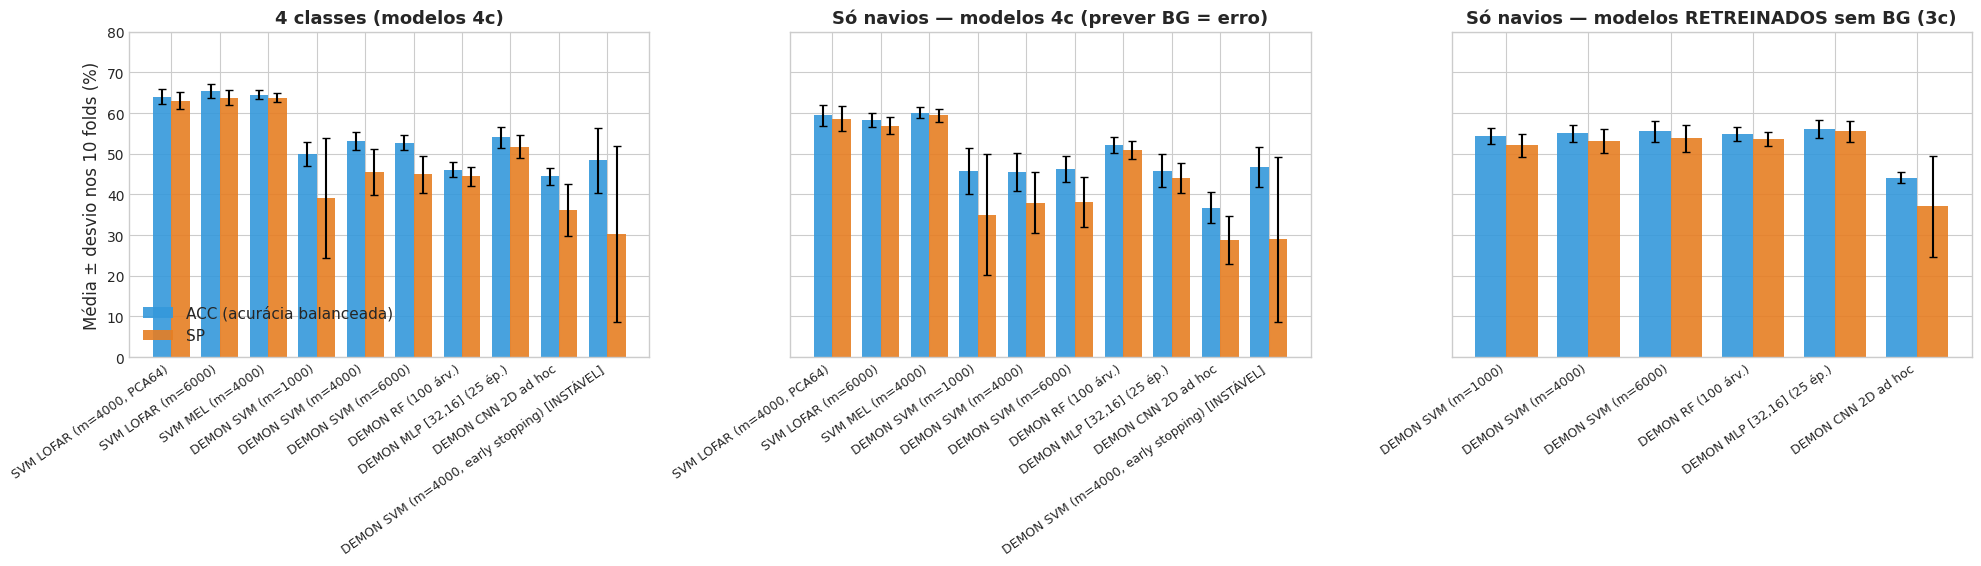

In [5]:
labels_4c = [l for l, _ in ROWS_4C]
labels_3c = [l for l, _, _ in ROWS_3C]
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8), sharey=True)
w = 0.38
for ax, labels, S, title in [
        (axes[0], labels_4c, S4, '4 classes (modelos 4c)'),
        (axes[1], labels_4c, SB, 'Só navios — modelos 4c (prever BG = erro)'),
        (axes[2], labels_3c, S3, 'Só navios — modelos RETREINADOS sem BG (3c)')]:
    x = np.arange(len(labels))
    ax.bar(x - w / 2, [S[l]['ACC'][0] for l in labels], w, yerr=[S[l]['ACC'][1] for l in labels], capsize=3,
           label='ACC (acurácia balanceada)', color='#3498db', alpha=0.9)
    ax.bar(x + w / 2, [S[l]['SP'][0] for l in labels], w, yerr=[S[l]['SP'][1] for l in labels], capsize=3,
           label='SP', color='#e67e22', alpha=0.9)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=35, ha='right', fontsize=9)
    ax.set_title(title, fontweight='bold')
    ax.set_ylim(0, 80)
axes[0].set_ylabel('Média ± desvio nos 10 folds (%)')
axes[0].legend(loc='lower left')
plt.tight_layout()
plt.show()

**Leitura da tabela (valores calculados acima):**
* Melhor SP 4c entre os modelos DEMON: **DEMON MLP [32,16] (25 ép.)** com **51,76 ± 2,75%**, contra 63,83 ± 1,91% (SVM LOFAR (m=6000)), 63,10 ± 2,19% (SVM LOFAR (m=4000, PCA64)) e 63,78 ± 1,14% (SVM MEL (m=4000)).
* **Modelos instáveis:** DEMON SVM (m=4000, early stopping) [INSTÁVEL] tem SP 30,25 ± 21,66% (SP por fold: 0,0, 22,0, 53,4, 47,7, 49,1, 0,0, 0,0, 36,8, 39,9, 53,6); o SVM DEMON m=1000 também tem desvio alto (39,15 ± 14,70%; folds: 53,9, 0,0, 39,5, 32,5, 36,9, 46,4, 51,2, 37,7, 42,0, 51,6). Um fold com SP = 0 significa que alguma classe teve recall zero naquele fold. A CNN 2D ad hoc fica em 36,28 ± 6,38% (recall SMALL 8,71%) e deve ser tratada como **colapsada**, não como baseline.
* O recall SMALL do SVM LOFAR m=6000 é **38,15%** (uma versão anterior trazia 42,58%).

## 4. Matrizes de Confusão (`m=4000` vs. `m=6000`, max_iter=1000)

Matrizes **acumuladas** nas 10 dobras (n = 6.390 instâncias arquivo × fold de teste nos modelos 4c; cada um dos 1.706 arquivos aparece em média 3,75 vezes no teste), normalizadas por linha. A diagonal acumulada difere ligeiramente do recall médio por fold da tabela.

In [6]:
CLS = ['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']


def confusion(exp, mode='4c'):
    """Matriz de confusão por arquivo, ACUMULADA nas 10 dobras (instâncias arquivo x fold), normalizada por linha (%)."""
    df = pd.concat(R.file_predictions(exp).values(), ignore_index=True)
    if mode == '4c_sem_bg':
        df = df[df.Target != 3]
    rows = sorted(df.Target.unique())
    cols = sorted(set(rows) | set(df.Prediction.unique()))
    cm = pd.crosstab(df.Target, df.Prediction).reindex(index=rows, columns=cols, fill_value=0)
    cmn = 100 * cm.div(cm.sum(axis=1), axis=0)
    cmn.index = [CLS[i] for i in rows]
    cmn.columns = [CLS[i] for i in cols]
    return cmn, int(cm.values.sum())


CMS = {
    ('m=4000', '4c'): confusion('svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_it1000_4c'),
    ('m=4000', '3c'): confusion('svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_it1000_3c'),
    ('m=6000', '4c'): confusion('svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000_4c'),
    ('m=6000', '3c'): confusion('svm_nystroem_6000_demon_C2.0_elasticnet_l1r0.15_it1000_3c'),
}
N_EVAL = CMS[('m=4000', '4c')][1]
N_FILES = len(set().union(*[set(d.File) for d in R.file_predictions('svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_it1000_4c').values()]))

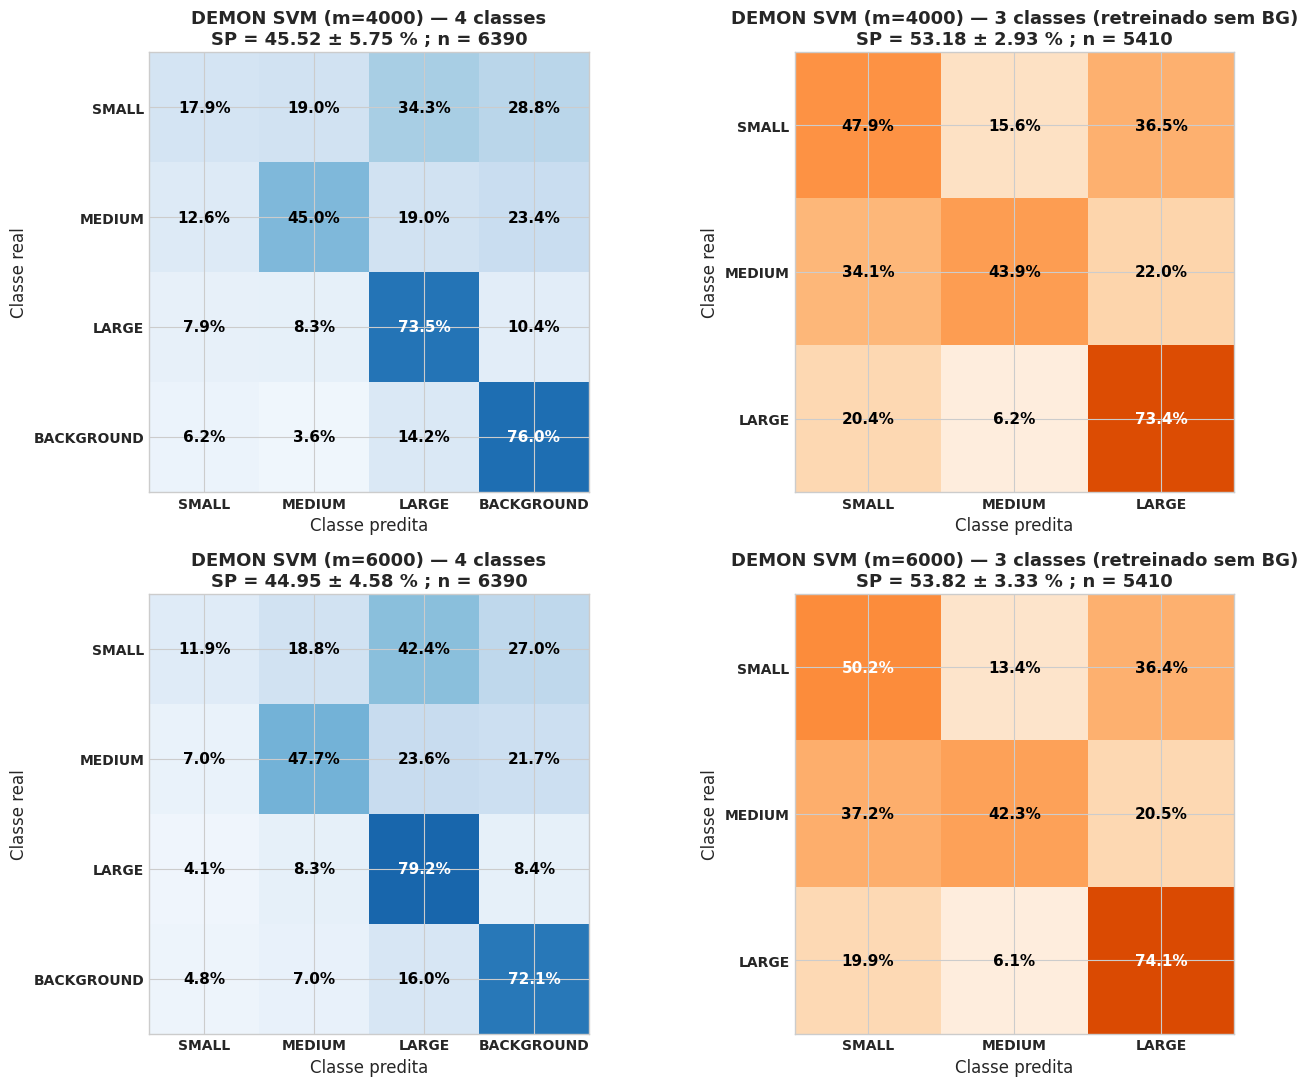

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (m, mode) in zip(axes.flatten(), CMS):
    cm, n = CMS[(m, mode)]
    lbl = f'DEMON SVM ({m})'
    sp = (S4 if mode == '4c' else S3)[lbl]['SP']
    ax.imshow(cm.values, cmap='Blues' if mode == '4c' else 'Oranges', vmin=0, vmax=100)
    ax.set_xticks(range(cm.shape[1])); ax.set_xticklabels(cm.columns, fontweight='bold')
    ax.set_yticks(range(cm.shape[0])); ax.set_yticklabels(cm.index, fontweight='bold')
    ax.set_xlabel('Classe predita'); ax.set_ylabel('Classe real')
    tag = '4 classes' if mode == '4c' else '3 classes (retreinado sem BG)'
    ax.set_title(f'{lbl} — {tag}\nSP = {sp[0]:.2f} ± {sp[1]:.2f} % ; n = {n}', fontweight='bold')
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            v = cm.values[i, j]
            ax.text(j, i, f'{v:.1f}%', ha='center', va='center', color='white' if v > 50 else 'black', fontweight='bold')
plt.tight_layout()
plt.show()

In [8]:
# F-test 5x2cv (Alpaydin), igual ao artigo, sobre o recall de LARGE por fold (modelos 4c)
PAIRS = [('DEMON SVM (m=6000)', 'SVM LOFAR (m=6000)'), ('DEMON SVM (m=6000)', 'SVM LOFAR (m=4000, PCA64)'),
         ('DEMON SVM (m=6000)', 'SVM MEL (m=4000)'), ('DEMON SVM (m=4000)', 'SVM LOFAR (m=4000, PCA64)'),
         ('DEMON SVM (m=4000)', 'SVM MEL (m=4000)')]
E4 = dict(ROWS_4C)
tests = []
for a, b in PAIRS:
    for met in ('R_LARGE', 'SP'):
        F, p = R.f_test_5x2(E4[a], E4[b], metric=met)
        tests.append({'A': a, 'B': b, 'métrica': met, 'média A': round(S4[a][met][0], 2),
                      'média B': round(S4[b][met][0], 2), 'F': round(F, 2), 'p': round(p, 4)})
df_tests = pd.DataFrame(tests)
display(df_tests)

,A,B,métrica,média A,média B,F,p
0,DEMON SVM (m=6000),SVM LOFAR (m=6000),R_LARGE,79.21,76.31,1.81,0.2665
1,DEMON SVM (m=6000),SVM LOFAR (m=6000),SP,44.95,63.83,13.19,0.0054
2,DEMON SVM (m=6000),"SVM LOFAR (m=4000, PCA64)",R_LARGE,79.21,74.91,1.17,0.4594
3,DEMON SVM (m=6000),"SVM LOFAR (m=4000, PCA64)",SP,44.95,63.10,11.23,0.0078
4,DEMON SVM (m=6000),SVM MEL (m=4000),R_LARGE,79.21,69.25,6.29,0.0278
5,DEMON SVM (m=6000),SVM MEL (m=4000),SP,44.95,63.78,15.75,0.0036
6,DEMON SVM (m=4000),"SVM LOFAR (m=4000, PCA64)",R_LARGE,73.46,74.91,0.64,0.7421
7,DEMON SVM (m=4000),"SVM LOFAR (m=4000, PCA64)",SP,45.52,63.10,8.11,0.0161
8,DEMON SVM (m=4000),SVM MEL (m=4000),R_LARGE,73.46,69.25,0.78,0.6572
9,DEMON SVM (m=4000),SVM MEL (m=4000),SP,45.52,63.78,7.80,0.0176


## 5. Diagnóstico Físico e Conclusões

### 5.1 Por que o DEMON isolado fica abaixo do MEL/LOFAR?
1. **Informação descartada:** o DEMON retém só a envoltória da banda de 1–2 kHz, modulada entre 0,39 e 25 Hz; descarta o espectro direto (linhas tonais de máquinas e a distribuição de energia de banda larga) que o MEL e o LOFAR usam.
2. **Confusão com o fundo:** nas matrizes acumuladas, **28,8%** (m=4000) e **27,0%** (m=6000) dos arquivos SMALL são classificados como BACKGROUND, e **34,3%** / **42,4%** como LARGE. *Hipótese (não testada aqui):* lanchas com pouca cavitação na banda de 1–2 kHz produzem envoltórias de baixa modulação, parecidas com o fundo.
3. **MEDIUM:** recall de MEDIUM 43,9% (m=4000) e 42,3% (m=6000) no modelo 3c, com 34,1% / 37,2% indo para SMALL. *Hipótese:* a classe MEDIUM é heterogênea (rebocadores, supridores, propulsão azimutal ou CPP), o que espalha as rotações nas duas direções.

### 5.2 Onde o DEMON se destaca?
* **LARGE:** o maior recall de LARGE entre os SVMs DEMON 4c é **79,21%** (DEMON SVM (m=6000)); referências: 76,31% (SVM LOFAR (m=6000)), 74,91% (SVM LOFAR (m=4000, PCA64)) e 69,25% (SVM MEL (m=4000)). F-test 5x2cv sobre o recall de LARGE (DEMON SVM (m=6000) contra cada referência): SVM LOFAR (m=6000): F = 1,81, p = 0,267; SVM LOFAR (m=4000, PCA64): F = 1,17, p = 0,459; SVM MEL (m=4000): F = 6,29, p = 0,028. Diferença significativa (p < 0,05) apenas contra SVM MEL (m=4000). Contra SVM LOFAR (m=6000), SVM LOFAR (m=4000, PCA64) o DEMON é **equivalente** em LARGE (dentro da variação entre folds), não superior. No modelo 3c, o maior recall de LARGE é 74,07% (DEMON SVM (m=6000)), mas não há referência MEL/LOFAR retreinada sem BG para comparar.
* **SMALL no modelo 3c:** retreinado sem BACKGROUND, o recall de SMALL do SVM DEMON vai a **50,22%** (m=6000) e 47,87% (m=4000), contra 11,85% / 17,92% no 4c. Esse aumento decorre de **mudar o problema** (retreino sem a classe BACKGROUND, que no 4c absorvia 27,0% dos SMALL no m=6000) e não é comparável a recalls de modelos 4c nem às referências MEL/LOFAR, que não foram retreinadas sem BG.

### 5.3 Diretriz para a Etapa B
* O DEMON **não** deve ser usado isoladamente.
* Pode ser testado na **Fusão Híbrida** (MEL + DEMON, Notebook 8) e como entrada de um **especialista em cascata** entre embarcações. Qualquer ganho dessas arquiteturas precisa ser demonstrado com o F-test 5x2cv contra o melhor baseline.